# Q2D | Train Linear Regression

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset (the first 584 days), so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- 4 time-ordered folds: each trains on the days before its validation block, scored by RMSE in rentals per day. A change is real only when its Δrmse clears 1 SE. The validation blocks cover 2012-02-05 to 2012-08-06, so no choice is checked on autumn or winter days.

**Feature set**
- Treatments pay off: `FeelsLike` capped in place of `Temp`, a clipped hinge on `Humidity`, `Season` in 3 groups, `Weekday` and `IsHoliday` back in and `IsWorkday` out take the closed form to 823.3 from 1144.9 on the raw attributes (SE 81.5), so every later model uses them.

**Closed form vs SGD**
- SGD's defaults already get there: plain SGD is within noise of the closed form (827.1 against 823.3, SE 4.1) after at most 11 epochs.

**Other hyperparameters**
- No setting beats the defaults: across all 24 schedule and `eta0` pairs, the closest (`adaptive` at 1, -4.0; `invscaling` at 0.1, -3.8) only tie.
- Steps too small or too large fail: 0.0001 and below stop too early under every schedule, `optimal` diverges at every step, and `constant` is worse at every step (+13.8 at best).

**Regularization**
- No penalty helps: every alpha is at or above no penalty on all 4 folds, and the cost grows with alpha.
- L1 bites first: at alpha 0.01, Lasso is worse by 31.8 and Ridge by 9.4, with Elastic Net between them, costing more as its share of L1 grows.
- Large penalties underfit, then predict the mean: Ridge at alpha 10 raises training and validation RMSE together (1337.8 and 2385.8), and Lasso at alpha 1 reaches Dummy's RMSE (2523.9 against 2521.6).
- Nothing to cure: the training to validation gap is a shift in time, not overfitting: Dummy, which cannot overfit, shows it too (1476.3 against 2521.6).

**Selected model**
- Ridge at alpha 0.000001, picked as required: the weakest penalty tried, equal to no penalty at 827.1.
- Trained on all 584 days and saved: 8 epochs, training RMSE 635.4 (584.6 on the folds, which never train on the last block).

**Loss by epoch**
- A clean descent: validation RMSE falls from about 1,360 after epoch 1 to about 827 by epoch 10 and never turns back up, so more epochs do not overfit.
- Drawn by refitting with `max_iter=k`; the hint's loop restarts the schedule.

**Reproducibility**
- Seed 42 for every SGD model; the time-ordered folds are fixed by date, with no shuffle.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

import Q2.consts as Q2_CONSTS
from Q2.utils import level_slopes
from consts import TEST_SIZE, CV_SPLITS, SEED, MAX_ITER, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIOS

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.1f}'.format)  # rentals; a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)
train_df, _ = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

ATTRIBUTES = ['Temp', 'FeelsLike', 'Humidity', 'Wind', 'Year', 'IsHoliday', 'IsWorkday', 'Season', 'Month', 'Weekday', 'Weather']
X, y = train_df[ATTRIBUTES], train_df[Q2_CONSTS.TARGET]
print(f"left out: {', '.join(column for column in train_df.columns if column not in ATTRIBUTES + [Q2_CONSTS.TARGET])}")

left out: ID, Date, Casual, Registered


# Setup

## Folds

In [3]:
# Each fold trains on every day before its validation block of 46 days, the way the model will predict the test days
# after the training days. The 4 blocks are the last 184 training days.
FOLDS = list(TimeSeriesSplit(n_splits=CV_SPLITS, test_size=Q2_CONSTS.CV_TEST_SIZE).split(X))
FOLD_LABELS = [f"{train_df['Date'].iloc[validation[0]]:%Y-%m-%d}" for _, validation in FOLDS]  # first validation day

pd.DataFrame({
	'training rows': [len(train) for train, _ in FOLDS],
	'training days with Year 1': [int(train_df['Year'].iloc[train].sum()) for train, _ in FOLDS],
	'first validation day': FOLD_LABELS,
	'last validation day': [f"{train_df['Date'].iloc[validation[-1]]:%Y-%m-%d}" for _, validation in FOLDS],
}, index=pd.RangeIndex(1, len(FOLDS) + 1, name='fold'))

,training rows,training days with Year 1,first validation day,last validation day
fold,,,,
1,400,35,2012-02-05,2012-03-21
2,446,81,2012-03-22,2012-05-06
3,492,127,2012-05-07,2012-06-21
4,538,173,2012-06-22,2012-08-06


## Runs

In [4]:
RUNS = {}  # every cross validation result, keyed by name

def build(model, shapes=None):
	"""The pipeline of one experiment: shapes, standardized columns, model (see PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=shapes)

def score(name, pipeline):
	"""Cross validate a pipeline and keep its result under name."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=FOLDS)

def table(names, baseline):
	"""The baseline's result, then each of names with its change against the baseline."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in [baseline, *names]}, baseline=baseline, folds=FOLDS, decimals=1)

def compare(baseline, candidate):
	"""The RMSE of both on every fold, beside the candidate's change on every fold."""
	PLOTTING.fold_comparison(runs=RUNS, baseline=baseline, candidate=candidate, folds=FOLDS, fold_labels=FOLD_LABELS, decimals=1)

def deltas(names, baseline):
	"""Each of names' change against the baseline on every fold, one row each."""
	PLOTTING.fold_deltas(runs=RUNS, baseline=baseline, names=names, folds=FOLDS)

# Method

- **Metric:** RMSE in rentals per day, on the validation days of each fold. The training RMSE next to it shows how much better a model fits the days it was trained on.
- **Folds:** four-fold cross validation in date order (`TimeSeriesSplit`): each fold trains on every day before its block of 46 validation days, so a model is always scored on days after the ones it learned from, as it will be on the test days. Every model is scored on the same 4 folds, so two models are compared fold by fold. Time-ordered folds cannot be reshuffled, so there are only 4 results per model. The 4 validation blocks run from 2012-02-05 to 2012-08-06 and the test days from 2012-08-07 to 2012-12-31, so no choice is validated on autumn or winter days.
- **Noise:** Δrmse is the mean change in validation RMSE against the baseline, and SE its standard error, widened because the folds share most of their training days (Nadeau and Bengio). With 4 folds, the SE rests on 4 differences, so it is a rough guide. Verdict: **candidate** when Δrmse is below -1 SE, **worse** when above +1 SE, **within noise** in between.
- **Carry rules:** a change is carried only when it is a candidate. Within noise, the simpler model stays: a feature change back to the raw attribute is taken, any other change is not, and a hyperparameter keeps its current value. Combined puts the carried feature changes together and is kept when its mean is below the strongest combination's.
- **Selected model:** the homework asks for one regularized model, so the regularized setting with the lowest mean validation RMSE is selected, even when it only ties the others.
- **Drop One:** an attribute stays in the model only when dropping it raises the mean validation RMSE (see Drop One).
- **Pipeline:** every model is one pipeline that takes the 11 raw attributes: shapes, standardized columns, model. The target is standardized too and the predictions turned back into rentals. Each step is fit on the training days of a fold only.
- **Shapes:** taken from Q2B's screens (`STATISTICS.shape_fits` for the continuous attributes, `STATISTICS.category_fits` with `Year` in the fit for `Season` and `Month`) with the settings they found. Those settings were searched on all training days, validation days included, so shape results are a little optimistic.
- **Optimism:** every choice is made on these folds, so their scores are a little optimistic. The test set gives the honest estimate.

# Baselines

## Dummy and Closed Form

In [5]:
score('Dummy', build(DummyRegressor()))  # predicts the training mean of every fold
score('Closed form', build(LinearRegression()))  # least squares on the 11 raw attributes, codes as numbers, solved by SVD

table(['Closed form'], baseline='Dummy')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Dummy,2521.6,1476.3,NaN,NaN,,baseline
Closed form,1144.9,710.0,-1376.7,358.3,4 of 4,candidate


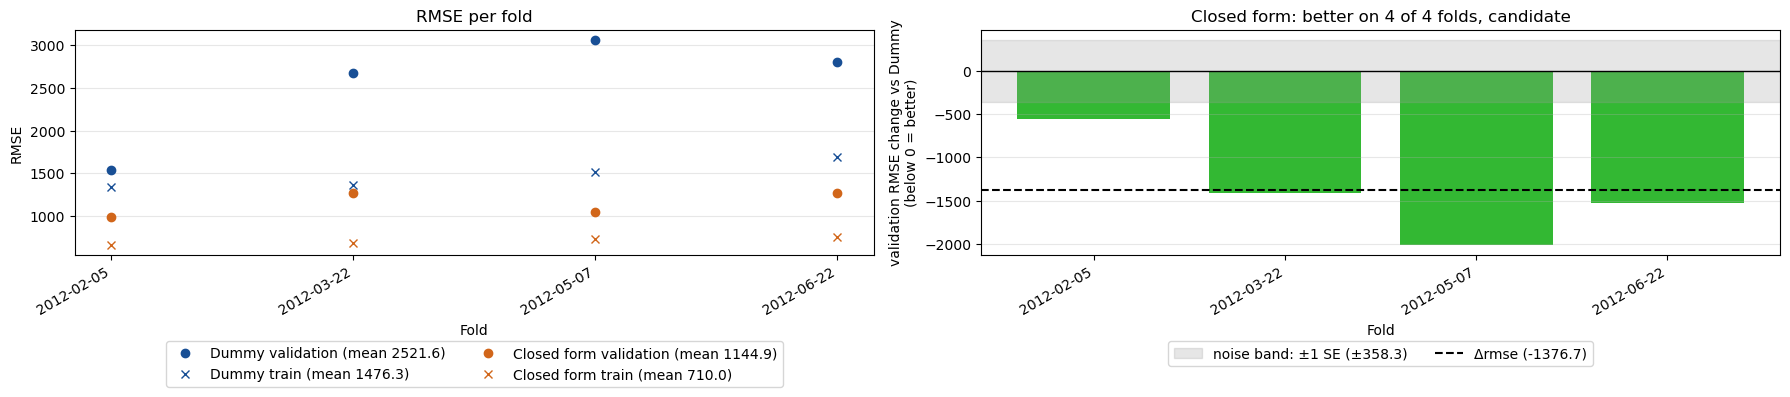

In [6]:
compare('Dummy', 'Closed form')

### Notes / Observations

- Closed form far ahead of the mean: validation RMSE 1144.9 against 2521.6 for Dummy, better on all 4 folds. This is the bar every later tier has to beat.
- The gap between training and validation is a shift in time, not overfitting: Dummy, which cannot overfit, shows the same kind of gap (training 1476.3 against validation 2521.6) as the closed form (710.0 against 1144.9). The validation days come after the training days and differ from them, so a penalty cannot close this gap.

# Feature Shapes

The strongest combination takes Q2B's recommended treatment for each attribute that has one. Each experiment then changes one thing against it, from Q2B's other treatments and Q2C's overlaps:

| Attribute | In the strongest combination | Tested against it |
|---|---|---|
| `FeelsLike` | cap at 0.573 | raw; `Temp` capped at 0.583 in its place (r 0.997 between them in Q2C) |
| `Temp` | dropped | (see `FeelsLike`) |
| `Humidity` | floor at 0.747 | raw; hinge at 0.699 with the one 0.0 day clipped up to 0.172 |
| `Month` | hinge at month 6 | the code as a number; one-hot; sine / cosine with 2 waves; its own slope of `FeelsLike` or of `Humidity` per month |
| `Season` | 3 groups: {1} \| {2, 4} \| {3} | the code as a number; one-hot; dropped (r 0.862 with `Month` in Q2C) |
| `Wind` | raw | windy day flag at 0.184; dropped |
| `Weather` | the code as a number | dropped (r 0.586 with `Humidity` in Q2C) |
| `Year` | raw | nothing: Q2B keeps it in every model |
| `Weekday`, `IsWorkday`, `IsHoliday` | dropped | the three back in, raw |

Every model in this section is the closed form.

In [7]:
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q2_CONSTS.TARGET) for attribute in Q2_CONSTS.CONTINUOUS}
FITS['Month'] = STATISTICS.category_fits(df=train_df, feature='Month', target=Q2_CONSTS.TARGET, period=12, control='Year')
FITS['Season'] = STATISTICS.category_fits(df=train_df, feature='Season', target=Q2_CONSTS.TARGET, control='Year')

def shape(attribute, name):
	"""Q2B's shape of an attribute by name (ex 'cap'), with the setting Q2B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

def by_month(attribute):
	"""Its own slope of the attribute in every month (Month 1 is the baseline), from Month and the attribute."""
	return FunctionTransformer(level_slopes, kw_args={'levels': list(range(1, 13))}), ['Month', attribute]

## Strongest Combination

In [8]:
SHAPES = {
	'Temp': 'drop',
	'FeelsLike': shape('FeelsLike', 'cap'),
	'Humidity': shape('Humidity', 'floor'),
	'Wind': 'passthrough',
	'Year': 'passthrough',
	'IsHoliday': 'drop',
	'IsWorkday': 'drop',
	'Season': shape('Season', '3 groups'),
	'Month': shape('Month', 'hinge'),
	'Weekday': 'drop',
	'Weather': 'passthrough',
}
score('Shapes', build(LinearRegression(), SHAPES))

table(['Shapes'], baseline='Closed form')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Closed form,1144.9,710.0,NaN,NaN,,baseline
Shapes,854.5,596.7,-290.4,89.1,4 of 4,candidate


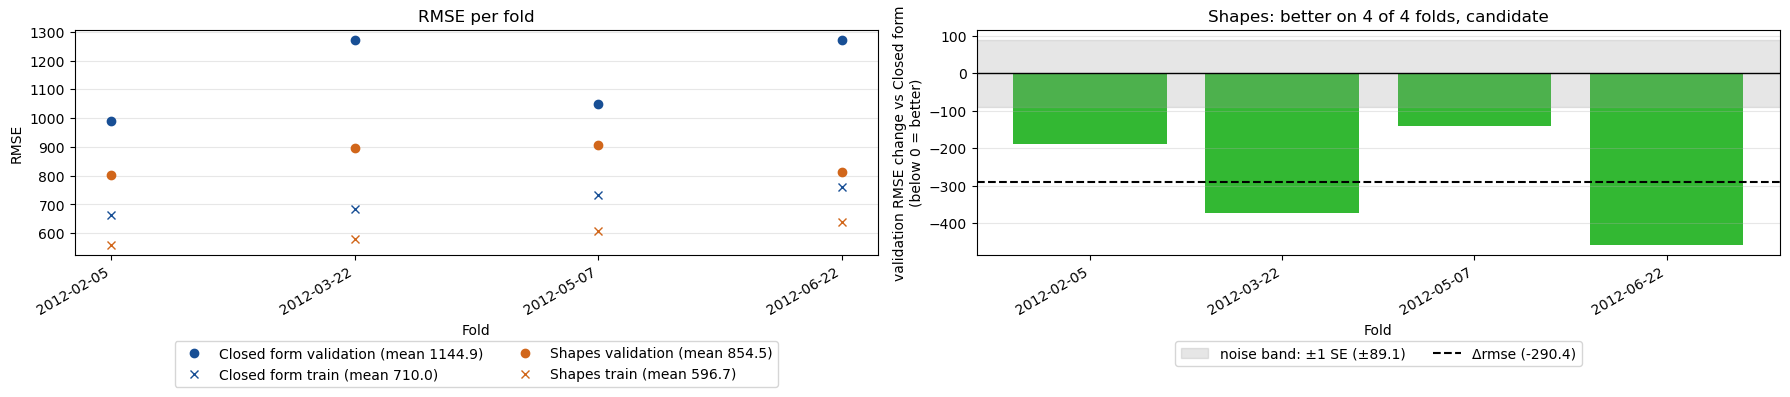

In [9]:
compare('Closed form', 'Shapes')

### Notes / Observations

- The treatments hold in the full model: validation RMSE falls to 854.5 from 1144.9 (-290.4, SE 89.1), better on all 4 folds, with 9 columns instead of 11.
- They narrow the time gap too: training RMSE falls less (710.0 to 596.7) than validation RMSE, so the shapes mostly help on the later days the straight lines missed.

## Experiments

Each row changes one thing against `Shapes`: an attribute back to raw, another treatment in place of the one used, columns added, or an attribute dropped.

In [10]:
HUMIDITY_CLIPPED_HINGE = make_pipeline(FunctionTransformer(np.clip, kw_args={'a_min': 0.172, 'a_max': None}), shape('Humidity', 'hinge'))

EXPERIMENTS = {
	'Raw: FeelsLike': {**SHAPES, 'FeelsLike': 'passthrough'},
	'Raw: Humidity': {**SHAPES, 'Humidity': 'passthrough'},
	'Raw: Month': {**SHAPES, 'Month': 'passthrough'},
	'Raw: Season': {**SHAPES, 'Season': 'passthrough'},
	'Swap: Temp cap for FeelsLike': {**SHAPES, 'FeelsLike': 'drop', 'Temp': shape('Temp', 'cap')},
	'Swap: Humidity clipped hinge': {**SHAPES, 'Humidity': HUMIDITY_CLIPPED_HINGE},
	'Swap: Month one-hot': {**SHAPES, 'Month': shape('Month', 'one-hot')},
	'Swap: Month sine / cosine': {**SHAPES, 'Month': shape('Month', 'sine / cosine, 2 waves')},
	'Swap: Season one-hot': {**SHAPES, 'Season': shape('Season', 'one-hot')},
	'Swap: Wind flag': {**SHAPES, 'Wind': shape('Wind', 'step')},
	'Add: FeelsLike by month': {**SHAPES, 'FeelsLike by month': by_month('FeelsLike')},
	'Add: Humidity by month': {**SHAPES, 'Humidity by month': by_month('Humidity')},
	'Add: Weekday, IsWorkday, IsHoliday': {**SHAPES, 'Weekday': 'passthrough', 'IsWorkday': 'passthrough', 'IsHoliday': 'passthrough'},
	'Drop: Wind': {**SHAPES, 'Wind': 'drop'},
	'Drop: Season': {**SHAPES, 'Season': 'drop'},
	'Drop: Weather': {**SHAPES, 'Weather': 'drop'},
}
for name, shapes in EXPERIMENTS.items():
	score(name, build(LinearRegression(), shapes))

table(list(EXPERIMENTS), baseline='Shapes')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Shapes,854.5,596.7,NaN,NaN,,baseline
Raw: FeelsLike,948.6,655.1,94.1,30.4,0 of 4,worse
Raw: Humidity,840.2,602.3,-14.3,21.0,3 of 4,within noise
Raw: Month,860.4,599.3,5.9,12.6,1 of 4,within noise
Raw: Season,913.7,603.3,59.2,41.1,1 of 4,worse
Swap: Temp cap for FeelsLike,855.1,593.7,0.6,4.6,1 of 4,within noise
Swap: Humidity clipped hinge,833.8,592.2,-20.7,15.8,3 of 4,candidate
Swap: Month one-hot,908.6,582.0,54.2,33.5,0 of 4,worse
Swap: Month sine / cosine,897.4,596.3,42.9,41.0,1 of 4,worse
Swap: Season one-hot,868.8,590.0,14.3,24.9,2 of 4,within noise


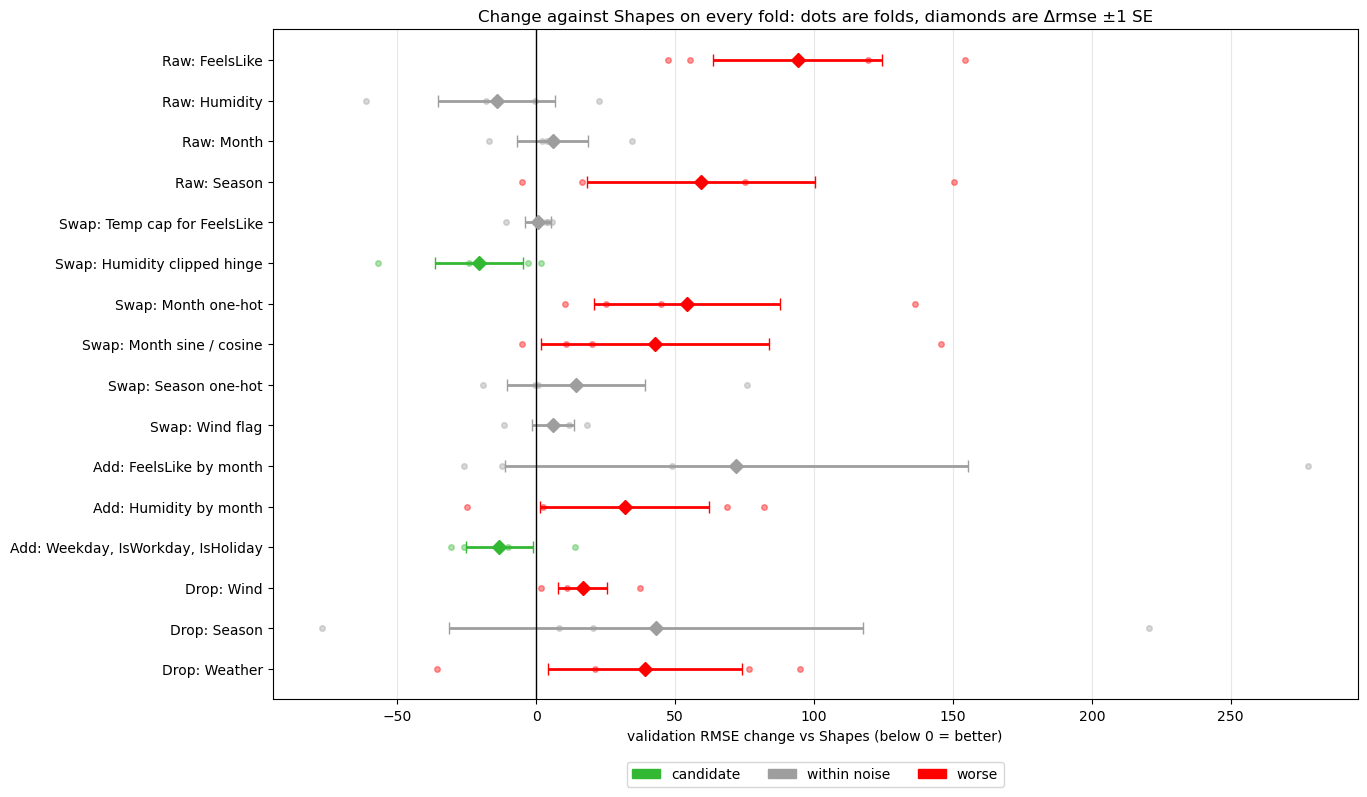

In [11]:
deltas(list(EXPERIMENTS), baseline='Shapes')

### Notes / Observations

- `FeelsLike`'s cap matters most: back to raw is worse by 94.1, on all 4 folds. `Temp`'s cap in its place ties (+0.6, SE 4.6), so either one works.
- `Month`'s and `Season`'s encodings are right: one-hot and sine / cosine for `Month` are worse (+54.2 and +42.9), and so is `Season` as a plain code (+59.2). `Month` as a plain code ties the hinge (+5.9, SE 12.6).
- `Humidity`'s floor is its weakest option: the clipped hinge beats it (-20.7, SE 15.8), and even raw `Humidity` ties it.
- The calendar flags help next to the other attributes: adding `Weekday`, `IsWorkday` and `IsHoliday` back is a candidate (-13.2, SE 12.0), better on 3 of 4 folds, although Q2B found they explain nothing on their own.
- A slope per month fits the training days, not the later ones: `Humidity` by month is worse (+31.9) while its training RMSE falls to 568.7, and `FeelsLike` by month swings by more than 250 on one fold.
- `Wind` and `Weather` earn their place (both drops worse), while dropping `Season` is within noise with the second widest SE of the table (74.5, after `FeelsLike` by month's 83.4).

## Combined

Every candidate, plus every change back to raw that is within noise (it makes the model simpler), together. A drop that is only within noise is left to Drop One, which removes one attribute at a time, so two attributes that cover for each other cannot leave together. When several rows touch the same attribute, the one with the lowest rmse wins. If Combined has a higher mean than `Shapes`, the best single change is carried instead.

In [12]:
COMBINED = {
	**SHAPES,
	'Humidity': HUMIDITY_CLIPPED_HINGE,  # candidate, and the lowest rmse of the 2 qualifying Humidity rows (raw is the other)
	'Month': 'passthrough',  # back to the plain code: within noise, and 1 column instead of 2
	'Weekday': 'passthrough',  # candidate (the three calendar attributes back in)
	'IsWorkday': 'passthrough',  # candidate
	'IsHoliday': 'passthrough',  # candidate
}  # dropping Season is within noise, so it is left to Drop One; the Temp cap swap and Season one-hot are within noise but not simpler, so they are not taken
score('Combined', build(LinearRegression(), COMBINED))

table(['Combined'], baseline='Shapes')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Shapes,854.5,596.7,NaN,NaN,,baseline
Combined,824.8,584.1,-29.7,31.3,2 of 4,within noise


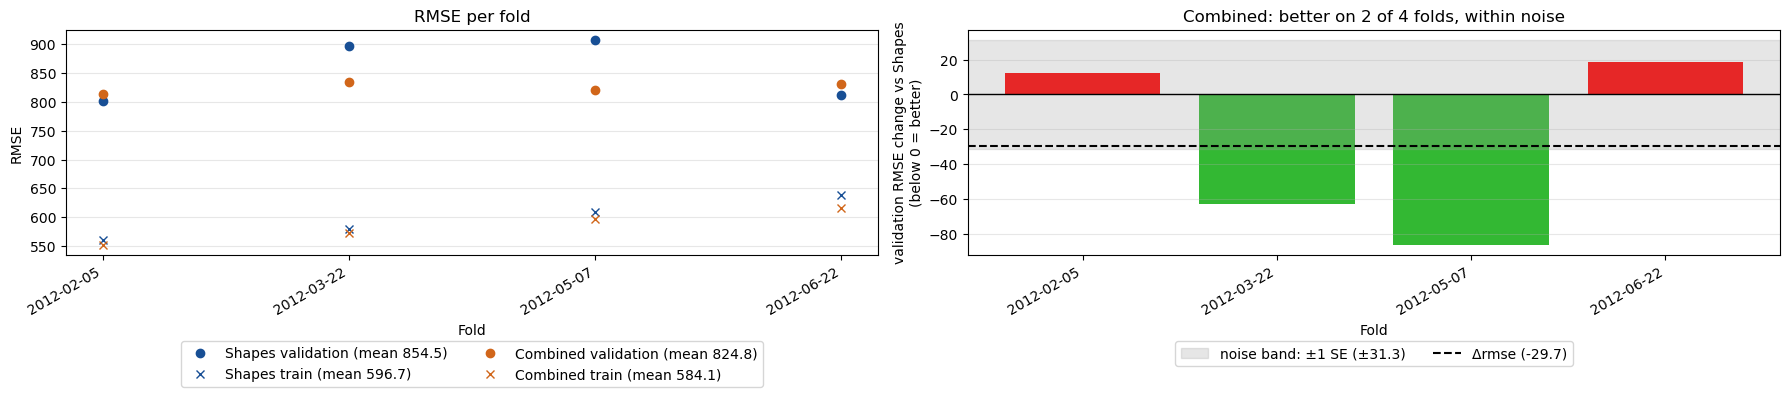

In [13]:
compare('Shapes', 'Combined')

### Notes / Observations

- The gain sits on the middle folds: Combined is better by 62 or more on the 2012-03-22 and 2012-05-07 blocks and slightly worse on the first and last, so overall it is within noise (-29.7, SE 31.3). It is carried because its mean is lower.
- Training RMSE falls less (596.7 to 584.1) than validation RMSE, so the changes help on the later days rather than fitting the training days closer.

# Drop One

Every attribute left in the model has to earn its place: dropping it must raise the mean validation RMSE. Each round drops every remaining attribute one at a time. When some drops do not raise the mean, the cheapest of them (the lowest rmse once dropped) first gets its other Q2B shapes, and one that beats the drop on the mean earns the attribute its place. Otherwise the attribute is dropped and the next round starts from the smaller model, so two attributes that cover for each other cannot leave together. The rounds end when every drop raises the mean.

The mean is used here, not the 1 SE rule: the 1 SE rule asks whether a change is real, while Drop One only asks whether the model is better with the attribute or without it. With only 4 time-ordered folds, the SE is too wide to confirm a cost the model really pays, and the rounds would strip attributes it needs.

In [14]:
def drop_one(shapes, prefix, model=LinearRegression()):
	"""Score the model (closed form unless given) of shapes with each attribute still in it dropped, one at a time, and return the run names."""
	names = []
	for attribute in ATTRIBUTES:
		if shapes.get(attribute) != 'drop':
			name = f'{prefix}: drop {attribute}'
			score(name, build(model, {**shapes, attribute: 'drop'}))
			names.append(name)
	return names

## Round 1

In [15]:
ROUND_1 = drop_one(COMBINED, 'Round 1')

table(ROUND_1, baseline='Combined')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Combined,824.8,584.1,NaN,NaN,,baseline
Round 1: drop FeelsLike,1084.5,820.5,259.7,163.4,0 of 4,worse
Round 1: drop Humidity,871.6,613.5,46.8,8.5,0 of 4,worse
Round 1: drop Wind,854.2,613.2,29.3,11.5,0 of 4,worse
Round 1: drop Year,1820.2,833.7,995.4,165.4,0 of 4,worse
Round 1: drop IsHoliday,826.5,587.5,1.7,5.8,2 of 4,within noise
Round 1: drop IsWorkday,823.3,584.2,-1.5,0.7,3 of 4,candidate
Round 1: drop Season,884.5,634.0,59.7,107.8,2 of 4,within noise
Round 1: drop Month,830.8,590.5,5.9,15.6,1 of 4,within noise
Round 1: drop Weekday,835.1,589.1,10.3,8.5,1 of 4,worse


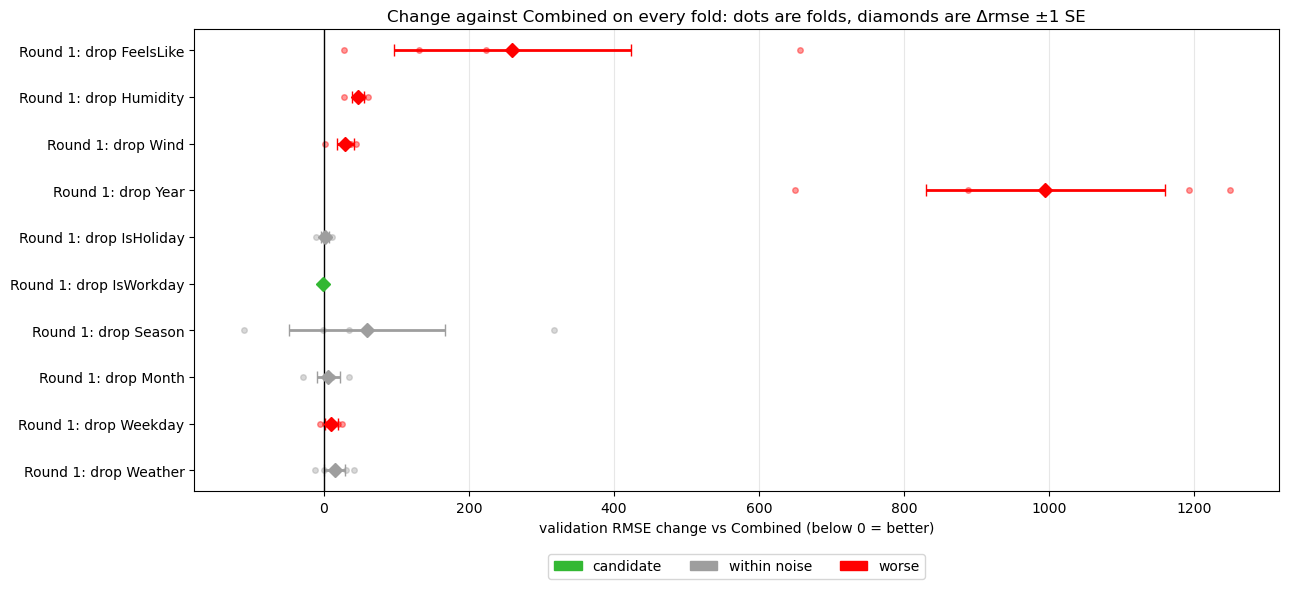

In [16]:
deltas(ROUND_1, baseline='Combined')

### Notes / Observations

- Only `IsWorkday` is not needed: dropping it lowers the mean (-1.5, SE 0.7), on 3 of 4 folds. With `Weekday` and `IsHoliday` in the model, it adds nothing they do not already carry.
- `Year` and `FeelsLike` carry the model: dropping them costs +995.4 and +259.7.
- `Season` stays on the mean, not on the 1 SE rule: its drop costs +59.7, but the SE is 107.8, so the 1 SE rule could not have shown it is needed.

### IsWorkday

Dropping `IsWorkday` lowers the mean validation RMSE. It is one 0/1 column, so it has no other Q2B shape to try, and it is dropped.

## Round 2

In [17]:
FEATURES = {**COMBINED, 'IsWorkday': 'drop'}
score('Closed form, features', build(LinearRegression(), FEATURES))
ROUND_2 = drop_one(FEATURES, 'Round 2')

table(ROUND_2, baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, features",823.3,584.2,NaN,NaN,,baseline
Round 2: drop FeelsLike,1085.7,822.4,262.3,163.3,0 of 4,worse
Round 2: drop Humidity,869.8,613.9,46.5,7.4,0 of 4,worse
Round 2: drop Wind,852.5,613.3,29.2,11.6,0 of 4,worse
Round 2: drop Year,1819.6,833.8,996.2,165.0,0 of 4,worse
Round 2: drop IsHoliday,825.6,588.0,2.2,4.2,2 of 4,within noise
Round 2: drop Season,882.9,634.0,59.6,107.7,2 of 4,within noise
Round 2: drop Month,829.3,590.6,5.9,15.5,1 of 4,within noise
Round 2: drop Weekday,833.7,589.2,10.4,8.5,1 of 4,worse
Round 2: drop Weather,837.8,606.8,14.5,15.9,1 of 4,within noise


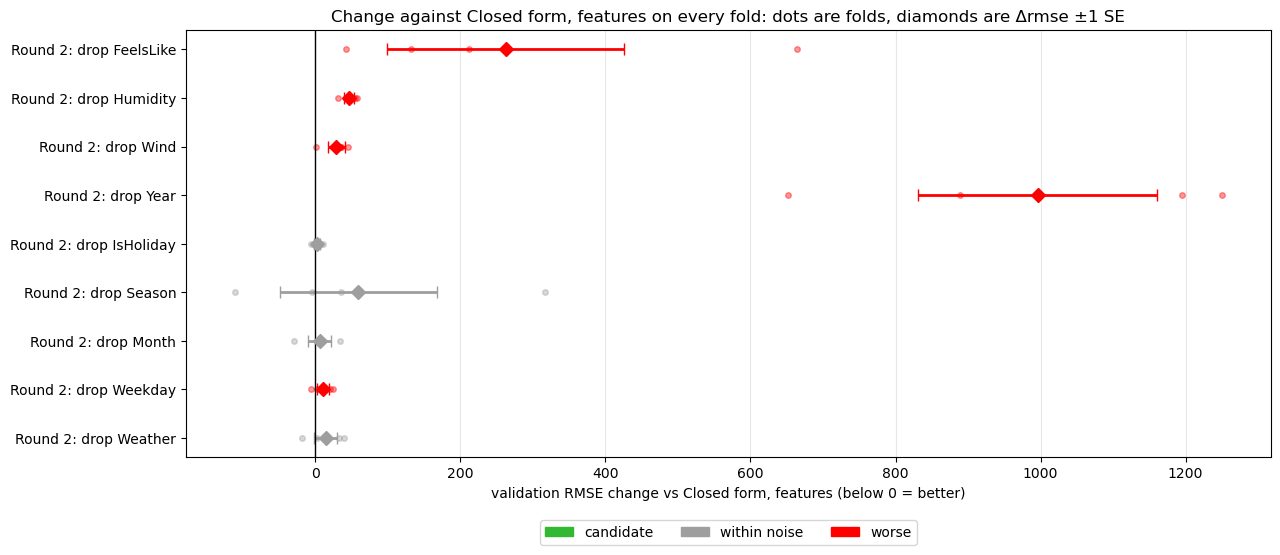

In [18]:
deltas(ROUND_2, baseline='Closed form, features')

### Notes / Observations

- The rounds end: every drop raises the mean. The closest calls are `IsHoliday` (+2.2, SE 4.2) and `Month` as a plain code (+5.9, SE 15.5), small but positive, so both stay.
- Nothing shifts once `IsWorkday` is gone: every drop costs within 3 rentals of what it cost in round 1, so `IsWorkday` was not covering for any other attribute.

# Carried Feature Set

The feature set every model from here on uses, against the closed form on the 11 raw attributes.

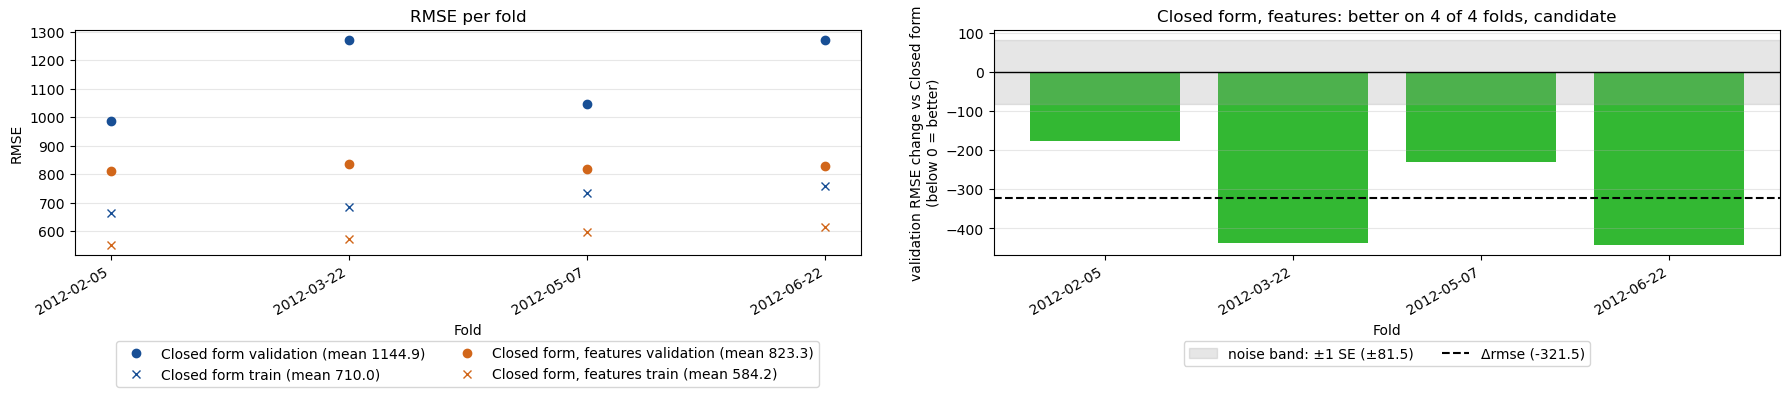

In [19]:
compare('Closed form', 'Closed form, features')

### Notes / Observations

- The carried feature set: 9 attributes in 11 columns, better than the 11 raw attributes by 321.5 (SE 81.5), on all 4 folds. The gain is largest on the 2012-03-22 and 2012-06-22 blocks (more than 400 each), where the raw model is worst.
- The time gap remains: training RMSE is 584.2 against 823.3 on validation. As in the Baselines, this comes from the validation days coming after the training days, so a penalty cannot close it.

# SGD

`SGDRegressor` on the carried feature set. Every setting is written out, none left to a default: `penalty=None` (the default is a light L2 penalty), the learning rate schedule, `eta0`, `power_t`, `max_iter` and `tol`. `max_iter` is only a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [20]:
YMAX = 2700  # a little above Dummy's RMSE: a run that diverges is drawn at the top of the chart instead of flattening the rest
SGD_SETTINGS = dict(
	penalty=None,
	learning_rate='invscaling',  # step = eta0 / t ** power_t, shrinking as training goes on
	eta0=0.01,
	power_t=0.25,
	average=False,
	max_iter=MAX_ITER,
	tol=1e-3,
	random_state=SEED,
)
SETTINGS = {}  # the settings of every SGD run, keyed by name

def sgd(name, settings):
	"""Cross validate SGD with these settings on the carried feature set, and keep the settings under name."""
	SETTINGS[name] = settings
	score(name, build(SGDRegressor(**settings), FEATURES))

def sweep(parameter, values, settings, baseline, prefix='', log_x=False):
	"""Cross validate SGD at each value of one parameter, the others at settings, and show the table and the chart
	against baseline. Return the run names, keyed by value."""
	names = {value: f'{prefix}{parameter}={value}' for value in values}
	for value, name in names.items():
		sgd(name, {**settings, parameter: value})
	display(table(list(names.values()), baseline=baseline))
	PLOTTING.parameter_search(
		runs={value: RUNS[name] for value, name in names.items()},
		parameter=parameter,
		log_x=log_x,
		reference=(baseline, RUNS[baseline]),
		ymax=YMAX,
		title=f'{prefix}{parameter}: RMSE on every fold',
	)
	return names

def cross(first, first_values, second, second_values, settings, baseline=None, prefix='', log_x=False):
	"""Cross validate SGD at every pair of values of two parameters, the others at settings, and show the table and the
	chart against baseline (the run at the current pair when omitted). Return the run names, keyed by pair. log_x
	applies to second."""
	names = {(a, b): f'{prefix}{first}={a}, {second}={b}' for a in first_values for b in second_values}
	for (a, b), name in names.items():
		sgd(name, {**settings, first: a, second: b})
	if baseline is None:
		baseline = names[(settings[first], settings[second])]
	display(table([name for name in names.values() if name != baseline], baseline=baseline))
	PLOTTING.parameter_cross(
		runs={pair: RUNS[name] for pair, name in names.items()},
		lines=first,
		x=second,
		log_x=log_x,
		reference=None if baseline in names.values() else (baseline, RUNS[baseline]),
		ymax=YMAX,
	)
	return names

def carried(names, current):
	"""The carry rule: of the runs in names (keyed by value) that are candidates against the run at current, the value
	with the lowest mean, or current when none is."""
	candidates = [
		value for value, name in names.items()
		if STATISTICS.fold_difference(baseline=RUNS[names[current]], candidate=RUNS[name], folds=FOLDS).verdict == 'candidate'
	]
	return min(candidates, key=lambda value: RUNS[names[value]]['validation rmse'].mean(), default=current)

## SGD vs Closed Form

In [21]:
sgd('SGD', SGD_SETTINGS)

table(['SGD'], baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Closed form, features",823.3,584.2,NaN,NaN,,baseline,<NA>
SGD,827.1,584.6,3.8,4.1,1 of 4,within noise,11


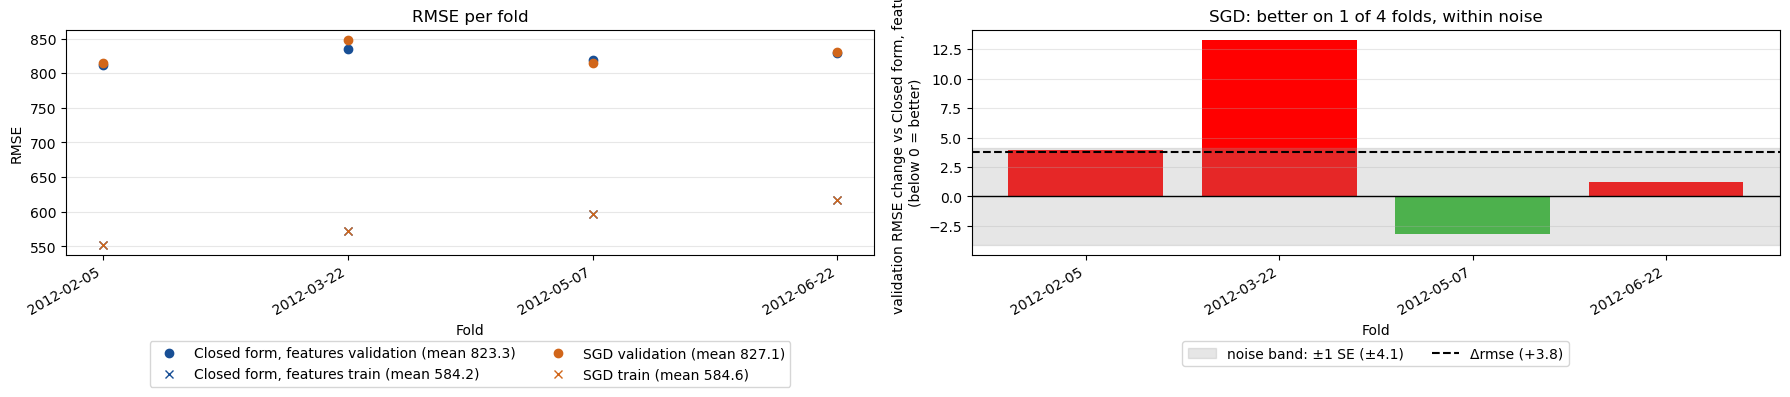

In [22]:
compare('Closed form, features', 'SGD')

### Notes / Observations

- Plain SGD lands near the closed form: 827.1 against 823.3, within noise (+3.8, SE 4.1), after at most 11 epochs.
- It stops a little short: SGD is worse on 3 of 4 folds. The default `invscaling` step ends the fit before the exact least squares coefficients.

## Hyperparameter Search

The learning rate schedule and its starting step `eta0` are searched together, every pair of the 4 schedules and 6 steps, since a schedule only sets how the step changes from `eta0`. The table compares each pair against the current settings (its baseline row), and a pair replaces them only when it is a candidate. Of several candidates, the lowest mean wins.

### Learning Rate Schedule × eta0 (Starting Step Size)

`optimal` sets its own step from `alpha` and ignores `eta0`, so its 6 rows are the same model.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"learning_rate=invscaling, eta0=0.01",827.1,584.6,NaN,NaN,,baseline,11
"learning_rate=constant, eta0=1e-05",1786.2,892.6,959.1,175.5,0 of 4,worse,142
"learning_rate=constant, eta0=0.0001",1077.9,619.8,250.8,90.4,0 of 4,worse,51
"learning_rate=constant, eta0=0.001",841.0,584.9,13.9,6.6,0 of 4,worse,14
"learning_rate=constant, eta0=0.01",841.0,601.4,13.8,13.3,1 of 4,worse,11
"learning_rate=constant, eta0=0.1",397845399313164.2,397879436303706.1,397845399312337.1,84553153856971.1,0 of 4,worse,6
"learning_rate=constant, eta0=1",8552222765629584.0,11548327091940132.0,8552222765628758.0,1298836337934844.8,0 of 4,worse,15
"learning_rate=optimal, eta0=1e-05",836756105336772.0,869488702102169.0,836756105335944.8,143579916810456.0,0 of 4,worse,154
"learning_rate=optimal, eta0=0.0001",836756105336772.0,869488702102169.0,836756105335944.8,143579916810456.0,0 of 4,worse,154
"learning_rate=optimal, eta0=0.001",836756105336772.0,869488702102169.0,836756105335944.8,143579916810456.0,0 of 4,worse,154


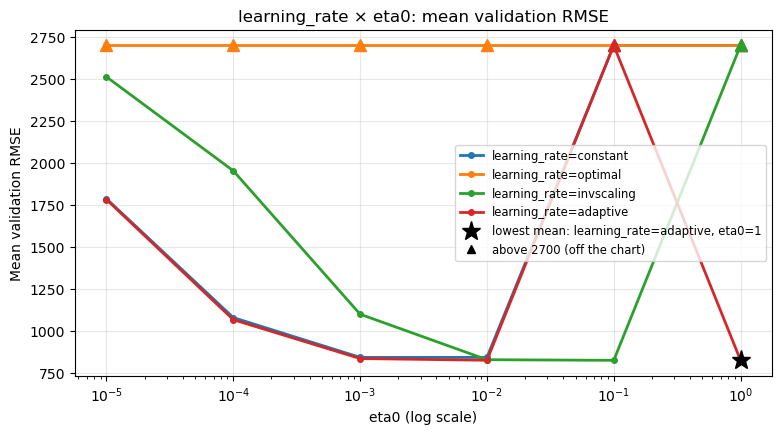

In [23]:
names = cross('learning_rate', LEARNING_RATE_SCHEDULES, 'eta0', ETA0S, SGD_SETTINGS, log_x=True)
learning_rate, eta0 = carried(names, (SGD_SETTINGS['learning_rate'], SGD_SETTINGS['eta0']))
SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': learning_rate, 'eta0': eta0}

### Notes / Observations

- No pair beats the defaults: `invscaling` with `eta0` 0.01 is kept. The closest, `adaptive` at 1 (-4.0, SE 5.1), `invscaling` at 0.1 (-3.8, SE 9.5) and `adaptive` at 0.01 (-3.3, SE 4.8), are all within noise.
- `constant` is worse at every step: its best, 0.001 and 0.01, both reach only 841.0 (+13.9 and +13.8).
- Too small a step stops too early: at 0.0001 and below, every schedule is worse by 238.4 or more.
- Too large a step diverges: `optimal` at every `eta0` (it ignores `eta0`), `constant` at 0.1 and 1, `invscaling` at 1 and `adaptive` at 0.1, while `adaptive` at 1 converges.

## Tuned SGD vs Closed Form

In [24]:
sgd('SGD, tuned', SGD_SETTINGS)
display(pd.Series(SGD_SETTINGS, name='carried').astype(str).to_frame())  # as text: the 1 decimal float format would show power_t 0.25 as 0.2 and tol 0.001 as 0.0

table(['SGD, tuned'], baseline='Closed form, features')

,carried
penalty,None
learning_rate,invscaling
eta0,0.01
power_t,0.25
average,False
max_iter,10000
tol,0.001
random_state,42


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Closed form, features",823.3,584.2,NaN,NaN,,baseline,<NA>
"SGD, tuned",827.1,584.6,3.8,4.1,1 of 4,within noise,11


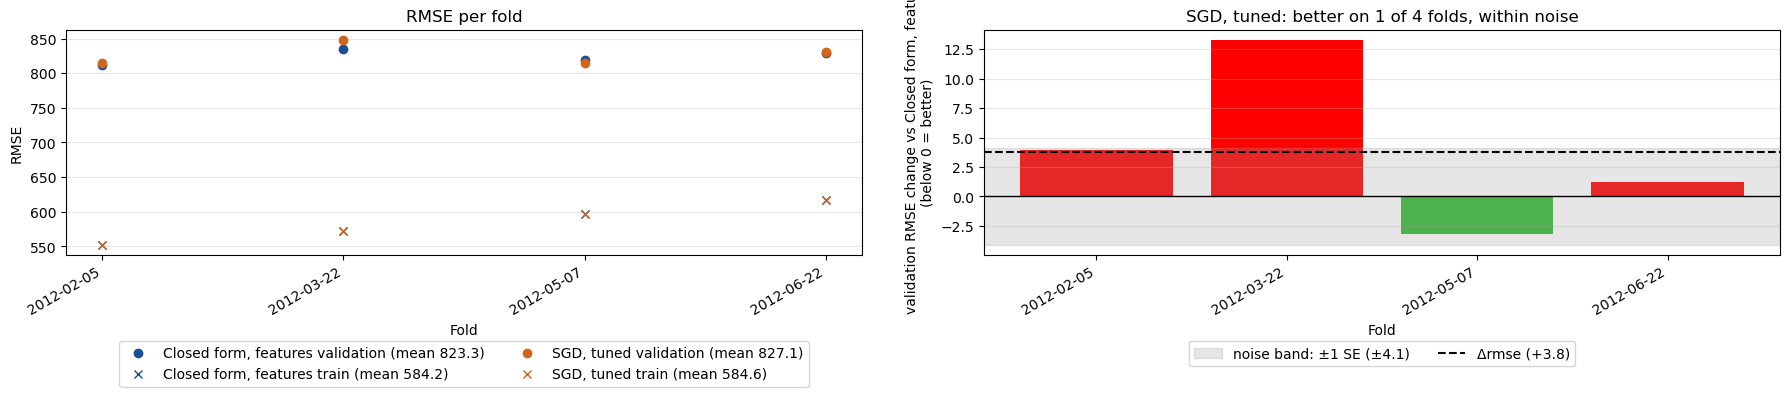

In [25]:
compare('Closed form, features', 'SGD, tuned')

### Notes / Observations

- The search changes nothing: no pair beats the defaults by 1 SE, so tuned SGD is plain SGD, within noise of the closed form (+3.8, SE 4.1).
- The time gap is untouched: training RMSE stays at 584.6.

# Regularization

The tuned SGD with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, a mix of both), each against the tuned SGD with no penalty. `alpha`, the penalty's strength, is tried at 8 values from 0.000001 to 10. Elastic Net also has `l1_ratio`, its share of L1 in the penalty, so it is searched over every pair of `alpha` and `l1_ratio`, as scikit-learn's `ElasticNetCV` does. SGD's `alpha` is not the same scale as `Ridge`'s: for L2, `Ridge(alpha=n * a)` matches `SGDRegressor(alpha=a)` on n rows.

## Ridge and Lasso

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",827.1,584.6,NaN,NaN,,baseline,11
"Ridge, alpha=1e-06",827.1,584.6,0.0,0.0,0 of 4,worse,11
"Ridge, alpha=1e-05",827.2,584.6,0.0,0.0,0 of 4,worse,11
"Ridge, alpha=0.0001",827.2,584.6,0.1,0.0,0 of 4,worse,11
"Ridge, alpha=0.001",828.1,584.6,0.9,0.5,0 of 4,worse,11
"Ridge, alpha=0.01",836.5,584.9,9.4,4.5,0 of 4,worse,11
"Ridge, alpha=0.1",937.0,598.9,109.8,37.7,0 of 4,worse,12
"Ridge, alpha=1",1692.3,874.8,865.2,140.6,0 of 4,worse,15
"Ridge, alpha=10",2385.8,1337.8,1558.7,328.7,0 of 4,worse,10


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",827.1,584.6,NaN,NaN,,baseline,11
"Lasso, alpha=1e-06",827.1,584.6,0.0,0.0,0 of 4,worse,11
"Lasso, alpha=1e-05",827.2,584.6,0.0,0.0,0 of 4,worse,11
"Lasso, alpha=0.0001",827.4,584.6,0.3,0.1,0 of 4,worse,11
"Lasso, alpha=0.001",829.9,584.7,2.8,1.3,0 of 4,worse,11
"Lasso, alpha=0.01",858.9,587.1,31.8,13.5,0 of 4,worse,11
"Lasso, alpha=0.1",1289.5,720.4,462.4,133.5,0 of 4,worse,15
"Lasso, alpha=1",2523.9,1476.3,1696.8,394.0,0 of 4,worse,6
"Lasso, alpha=10",2523.9,1476.3,1696.8,394.0,0 of 4,worse,6


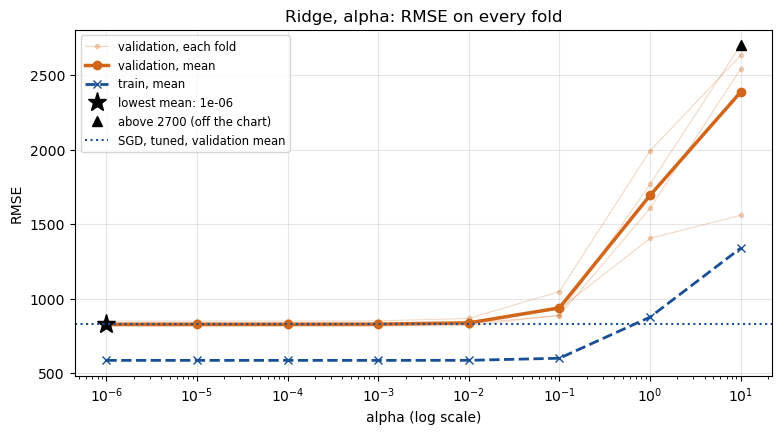

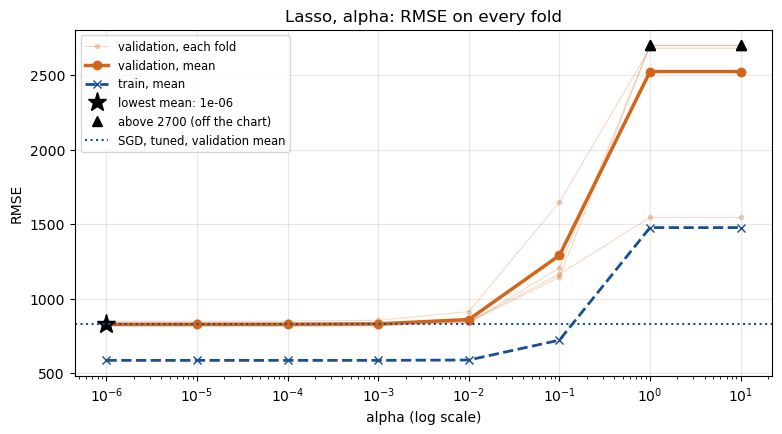

In [26]:
REGULARIZED = []  # every regularized run, the pool the selected model is picked from
for penalty, label in (('l2', 'Ridge'), ('l1', 'Lasso')):
	REGULARIZED += sweep('alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': penalty}, baseline='SGD, tuned', prefix=f'{label}, ', log_x=True).values()

### Notes / Observations

- No penalty helps: every alpha is at or above no penalty on all 4 folds, and the cost grows with alpha. The "worse" verdicts below alpha 0.001 are changes under 1 rental: the change is almost the same on every fold, so its SE rounds to 0.
- L1 bites first: at alpha 0.01, Lasso is worse by 31.8 and Ridge by 9.4.
- Too strong a penalty underfits: training and validation RMSE rise together (Ridge at alpha 10: 1337.8 and 2385.8), the sign of a model too simple, not of one fit to noise.
- Lasso from alpha 1 reaches Dummy's RMSE (2523.9 against 2521.6): the penalty pushes every coefficient to 0, leaving only the mean.
- No penalty narrows the time gap: up to alpha 0.001, training RMSE stays at 584.6. The gap between training and validation days is not overfitting, so there is nothing for a penalty to remove.

## Elastic Net: l1_ratio × alpha

Every pair of the 6 `l1_ratio` values and the 8 `alpha` values. `l1_ratio` 0 would be Ridge and 1 would be Lasso.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",827.1,584.6,NaN,NaN,,baseline,11
"Elastic Net, l1_ratio=0.1, alpha=1e-06",827.1,584.6,0.0,0.0,0 of 4,worse,11
"Elastic Net, l1_ratio=0.1, alpha=1e-05",827.2,584.6,0.0,0.0,0 of 4,worse,11
"Elastic Net, l1_ratio=0.1, alpha=0.0001",827.3,584.6,0.1,0.1,0 of 4,worse,11
"Elastic Net, l1_ratio=0.1, alpha=0.001",828.2,584.6,1.1,0.5,0 of 4,worse,11
"Elastic Net, l1_ratio=0.1, alpha=0.01",838.5,585.0,11.4,5.2,0 of 4,worse,11
"Elastic Net, l1_ratio=0.1, alpha=0.1",966.1,604.1,138.9,44.6,0 of 4,worse,15
"Elastic Net, l1_ratio=0.1, alpha=1",1952.6,994.7,1125.4,173.2,0 of 4,worse,15
"Elastic Net, l1_ratio=0.1, alpha=10",2523.9,1476.3,1696.8,394.0,0 of 4,worse,6
"Elastic Net, l1_ratio=0.15, alpha=1e-06",827.1,584.6,0.0,0.0,0 of 4,worse,11


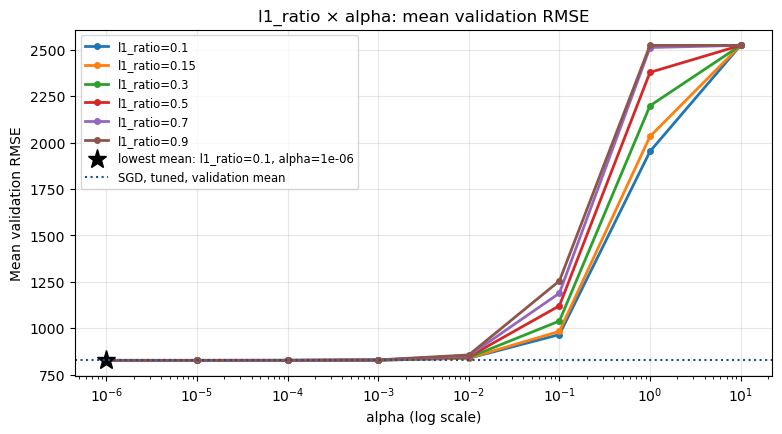

In [27]:
REGULARIZED += cross('l1_ratio', L1_RATIOS, 'alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': 'elasticnet'}, baseline='SGD, tuned', prefix='Elastic Net, ', log_x=True).values()

### Notes / Observations

- The best alpha is the weakest: every pair is worse than no penalty, so the lowest mean is at alpha 0.000001. There the penalty barely acts (Ridge, Lasso and every `l1_ratio` give 827.1), so the mix has almost nothing to change.
- Once the penalty acts, more L1 costs more: at alpha 0.01 the cost grows from +11.4 (`l1_ratio` 0.1) to +29.3 (0.9), between Ridge's +9.4 and Lasso's +31.8.
- Strong penalties reach the mean sooner with more L1: at alpha 1, `l1_ratio` 0.9 is already at the mean (2523.9, against Dummy's 2521.6) while 0.1 is at 1952.6. At alpha 10 every ratio is.

## Selected Model

The regularized setting with the lowest mean validation RMSE, against the tuned SGD with no penalty.

In [28]:
SELECTED = min(REGULARIZED, key=lambda name: RUNS[name]['validation rmse'].mean())
display(pd.Series(SETTINGS[SELECTED], name=SELECTED).astype(str).to_frame())  # as text: the 1 decimal float format would show a small alpha as 0.0

table([SELECTED], baseline='SGD, tuned')

,"Ridge, alpha=1e-06"
penalty,l2
learning_rate,invscaling
eta0,0.01
power_t,0.25
average,False
max_iter,10000
tol,0.001
random_state,42
alpha,1e-06


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",827.1,584.6,NaN,NaN,,baseline,11
"Ridge, alpha=1e-06",827.1,584.6,0.0,0.0,0 of 4,worse,11


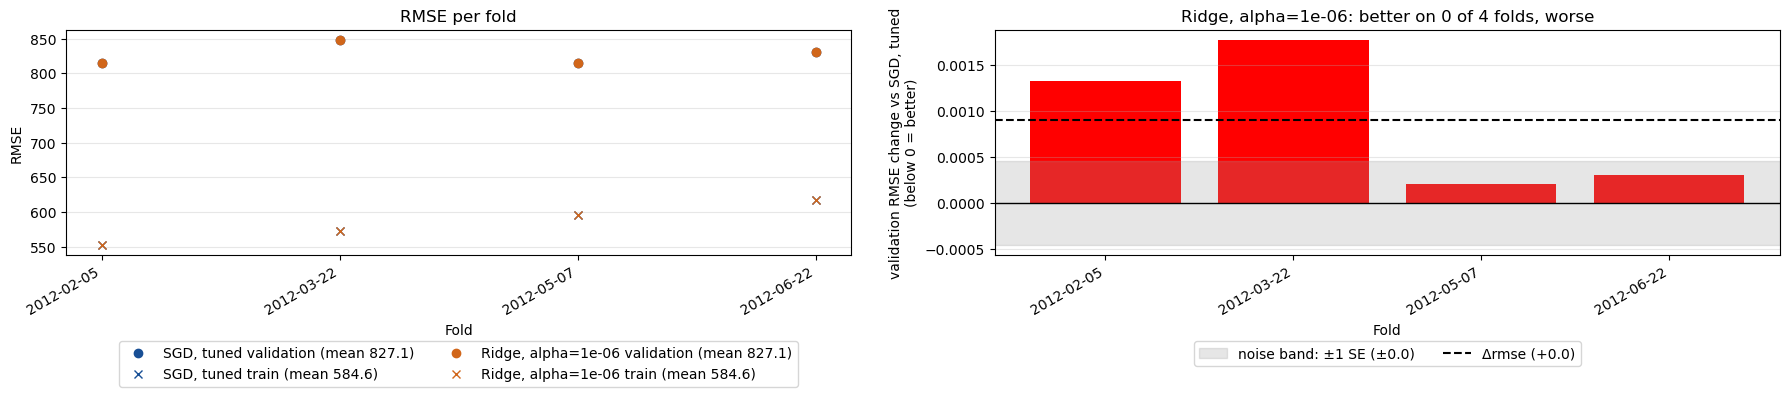

In [29]:
compare('SGD, tuned', SELECTED)

### Notes / Observations

- Selected as required, not because it helps: Ridge at alpha 0.000001, the weakest penalty tried, has the lowest mean of the regularized runs and equals no penalty (827.1). Its "worse" verdict is a change below 0.1 rental.

## Train on the Entire Training Set

The selected model refit on all 584 training days and saved. The saved pipeline takes the 11 raw attributes and builds its own columns.

In [30]:
final = build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES).fit(X, y)
Q2_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q2_CONSTS.MODEL_OUTPUT_DIR / 'linear_regression.joblib')

pd.Series({
	'training rows': len(X),
	'epochs run': PIPELINES.final_model(final).n_iter_,
	'train rmse': mean_squared_error(y, final.predict(X), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Ridge, alpha=1e-06"
training rows,584
epochs run,8
train rmse,635.4


## Training and Validation Loss by Epoch

The hint's `warm_start` loop restarts the learning rate schedule on every `fit` call, so epoch k here is a fresh fit with `max_iter=k` and the same seed, exactly the selected model's first k epochs. Once a fold's fit stops on its own (`tol`), its line stays flat. Shown on the 4 time-ordered folds.

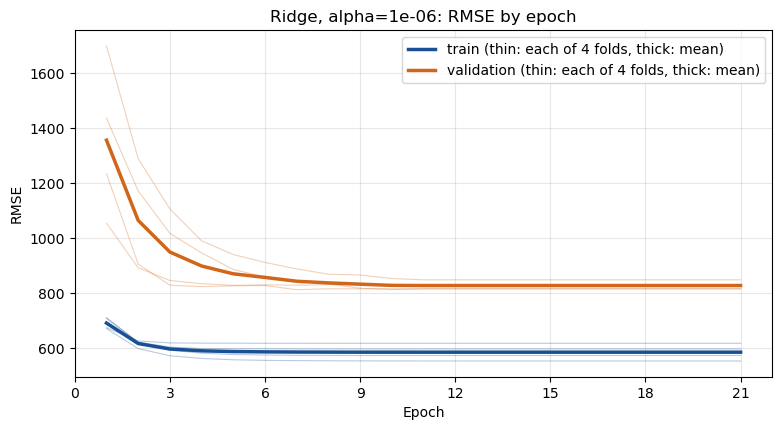

In [31]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max()) + 10  # past the last fold's stop, where every line is flat
curve = PIPELINES.epoch_rmse(pipeline=build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES), X=X, y=y, folds=FOLDS, epochs=EPOCHS)
PLOTTING.loss_curve(curve=curve, title=f'{SELECTED}: RMSE by epoch');

### Notes / Observations

- The full fit stops after 8 epochs, at a training RMSE of 635.4, above the 584.6 averaged over the folds: the full fit also trains on the last 46 days, which no fold trains on.
- A clean descent: validation RMSE falls fastest in the first epochs, from about 1,360 after epoch 1, and is flat at about 827 by epoch 10, when the folds stop.
- No overfitting with more epochs: validation RMSE never turns back up. The gap to training RMSE that remains is the time gap of the Baselines, not a sign of overfitting.